
# EuroSAT RGB — Machine Learning Baseline

## 1. Objective

The objective of this notebook is to establish an initial Machine Learning baseline for the EuroSAT RGB land cover classification task.

A Logistic Regression classifier will be trained using RGB colour histogram features extracted from individual satellite images.

## 2. Experimental Approach

The experiment follows these steps:

1. Load and validate the dataset split manifest.
2. Extract colour histogram features from each image.
3. Prepare training and validation datasets.
4. Train a Logistic Regression classifier.
5. Evaluate its performance using classification metrics.
6. Analyse classification errors and model limitations.

## 3. Feature Representation

Each RGB image is represented using a normalized colour histogram with 16 bins per channel.

This produces a feature vector with 48 dimensions per image.

The representation captures colour distributions but does not preserve spatial information.

## 4. Evaluation Strategy

The training set will be used to fit the model, while the validation set will be used to assess performance and guide subsequent experiments.

The test set will remain untouched until the final model evaluation.

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from math import ceil

print(f"Python version: {sys.version.split()[0]}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")

Python version: 3.11.9
NumPy version: 2.4.6
Pandas version: 3.1.0
Scikit-learn version: 1.9.1


In [27]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_DIR = PROJECT_ROOT / "data" / "raw" / "EuroSAT_RGB"
MANIFEST_PATH = (
    PROJECT_ROOT / "data" / "processed" / "split_manifest.csv"
)

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATASET_DIR}"
    )

if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(
        f"Split manifest not found: {MANIFEST_PATH}. "
        "Run scripts/create_splits.py first."
    )

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset directory: {DATASET_DIR}")
print(f"Split manifest: {MANIFEST_PATH}")

Project root: c:\Users\carla.lamas\Documents\P-Personal\landcover-lab
Dataset directory: c:\Users\carla.lamas\Documents\P-Personal\landcover-lab\data\raw\EuroSAT_RGB
Split manifest: c:\Users\carla.lamas\Documents\P-Personal\landcover-lab\data\processed\split_manifest.csv


In [28]:
manifest = pd.read_csv(MANIFEST_PATH)

required_columns = {"filepath", "label", "split"}

if not required_columns.issubset(manifest.columns):
    raise ValueError(
        f"Missing required columns: "
        f"{required_columns - set(manifest.columns)}"
    )

if manifest["filepath"].duplicated().any():
    raise ValueError("Duplicate image paths found.")

if manifest.isna().any().any():
    raise ValueError("Missing values found in the split manifest.")

print(f"Total samples: {len(manifest):,}")

display(manifest.head())

Total samples: 27,000


,filepath,label,split
0,data/raw/EuroSAT_RGB/Residential/Residential_2...,Residential,train
1,data/raw/EuroSAT_RGB/SeaLake/SeaLake_1784.jpg,SeaLake,train
2,data/raw/EuroSAT_RGB/Residential/Residential_2...,Residential,train
3,data/raw/EuroSAT_RGB/AnnualCrop/AnnualCrop_361...,AnnualCrop,train
4,data/raw/EuroSAT_RGB/Forest/Forest_1198.jpg,Forest,train


In [29]:

train_manifest = (
    manifest.loc[manifest["split"] == "train"]
    .reset_index(drop=True)
)

validation_manifest = (
    manifest.loc[manifest["split"] == "validation"]
    .reset_index(drop=True)
)

test_manifest = (
    manifest.loc[manifest["split"] == "test"]
    .reset_index(drop=True)
)

split_summary = pd.DataFrame(
    {
        "split": ["train", "validation", "test"],
        "samples": [
            len(train_manifest),
            len(validation_manifest),
            len(test_manifest),
        ],
    }
)

split_summary["percentage"] = (
    split_summary["samples"] / len(manifest) * 100
)

display(split_summary)

print("\nTraining class distribution:")
display(
    train_manifest["label"]
    .value_counts()
    .sort_index()
)

,split,samples,percentage
0,train,18900,70.0
1,validation,4050,15.0
2,test,4050,15.0



Training class distribution:


label
AnnualCrop              2100
Forest                  2100
HerbaceousVegetation    2100
Highway                 1750
Industrial              1750
Pasture                 1400
PermanentCrop           1750
Residential             2100
River                   1750
SeaLake                 2100
Name: count, dtype: int64

## 5. RGB Colour Histogram Feature Extraction

Each image is transformed into a numerical feature vector using normalized RGB colour histograms.

Sixteen histogram bins are computed independently for each colour channel, resulting in 48 features per image.

The resulting representation captures global colour distributions but does not preserve spatial information.

In [30]:
FEATURE_BINS = 16
CHANNEL_NAMES = ["Red", "Green", "Blue"]


def extract_rgb_histogram(
    image_path: Path,
    bins: int = FEATURE_BINS,
) -> np.ndarray:
    """Extract normalized RGB colour histograms from an image."""
    with Image.open(image_path) as image:
        pixels = np.asarray(
            image.convert("RGB"),
            dtype=np.uint8,
        )

    pixel_count = pixels.shape[0] * pixels.shape[1]

    channel_histograms = []

    for channel_index in range(3):
        histogram, _ = np.histogram(
            pixels[:, :, channel_index],
            bins=bins,
            range=(0, 256),
        )

        normalized_histogram = (
            histogram.astype(np.float32) / pixel_count
        )

        channel_histograms.append(normalized_histogram)

    return np.concatenate(channel_histograms)


def build_feature_matrix(
    split_data: pd.DataFrame,
) -> tuple[np.ndarray, np.ndarray]:
    """Build a feature matrix and label array from image paths."""
    feature_count = FEATURE_BINS * 3

    X = np.empty(
        (len(split_data), feature_count),
        dtype=np.float32,
    )

    y = split_data["label"].to_numpy()

    for index, row in enumerate(
        split_data.itertuples(index=False),
        start=1,
    ):
        image_path = PROJECT_ROOT / row.filepath

        if not image_path.is_file():
            raise FileNotFoundError(
                f"Image not found: {image_path}"
            )

        X[index - 1] = extract_rgb_histogram(image_path)

        if index % 3000 == 0 or index == len(split_data):
            print(
                f"Processed {index:,}/{len(split_data):,} images."
            )

    if not np.isfinite(X).all():
        raise ValueError("Non-finite feature values detected.")

    histogram_sums = X.reshape(
        -1,
        3,
        FEATURE_BINS,
    ).sum(axis=2)

    if not np.allclose(histogram_sums, 1.0, atol=1e-6):
        raise ValueError("Feature histogram normalization failed.")

    return X, y

In [31]:
sample_row = train_manifest.iloc[0]

sample_path = PROJECT_ROOT / sample_row["filepath"]
sample_features = extract_rgb_histogram(sample_path)

print(f"Image: {sample_path.name}")
print(f"Label: {sample_row['label']}")
print(f"Feature vector shape: {sample_features.shape}")
print(f"Data type: {sample_features.dtype}")

channel_sums = sample_features.reshape(
    3,
    FEATURE_BINS,
).sum(axis=1)

print("\nHistogram sum per channel:")
for channel_name, channel_sum in zip(
    CHANNEL_NAMES,
    channel_sums,
):
    print(f"{channel_name}: {channel_sum:.6f}")

Image: Residential_238.jpg
Label: Residential
Feature vector shape: (48,)
Data type: float32

Histogram sum per channel:
Red: 1.000000
Green: 1.000000
Blue: 1.000000


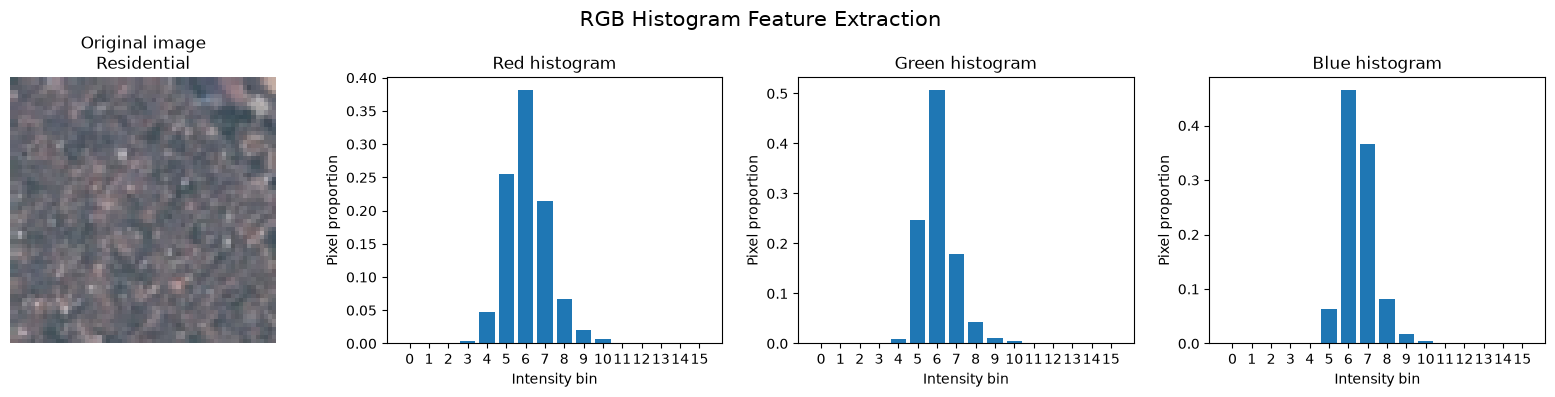

In [32]:
with Image.open(sample_path) as image:
    sample_image = np.asarray(image.convert("RGB"))

sample_histograms = sample_features.reshape(
    3,
    FEATURE_BINS,
)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(sample_image)
axes[0].set_title(f"Original image\n{sample_row['label']}")
axes[0].axis("off")

for index, channel_name in enumerate(CHANNEL_NAMES):
    axes[index + 1].bar(
        np.arange(FEATURE_BINS),
        sample_histograms[index],
    )

    axes[index + 1].set_title(f"{channel_name} histogram")
    axes[index + 1].set_xlabel("Intensity bin")
    axes[index + 1].set_ylabel("Pixel proportion")
    axes[index + 1].set_xticks(range(FEATURE_BINS))

fig.suptitle(
    "RGB Histogram Feature Extraction",
    fontsize=15,
)

fig.tight_layout()
plt.show()

In [33]:
print("Building training feature matrix...")

X_train, y_train = build_feature_matrix(train_manifest)

print("\nTraining feature extraction completed.")
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_train data type: {X_train.dtype}")
print(f"y_train data type: {y_train.dtype}")

Building training feature matrix...
Processed 3,000/18,900 images.
Processed 6,000/18,900 images.
Processed 9,000/18,900 images.
Processed 12,000/18,900 images.
Processed 15,000/18,900 images.
Processed 18,000/18,900 images.
Processed 18,900/18,900 images.

Training feature extraction completed.
X_train shape: (18900, 48)
y_train shape: (18900,)
X_train data type: float32
y_train data type: object


In [34]:
print("Building validation feature matrix...")

X_validation, y_validation = build_feature_matrix(
    validation_manifest
)

print("\nValidation feature extraction completed.")
print(f"X_validation shape: {X_validation.shape}")
print(f"y_validation shape: {y_validation.shape}")
print(f"X_validation data type: {X_validation.dtype}")
print(f"y_validation data type: {y_validation.dtype}")

Building validation feature matrix...
Processed 3,000/4,050 images.
Processed 4,050/4,050 images.

Validation feature extraction completed.
X_validation shape: (4050, 48)
y_validation shape: (4050,)
X_validation data type: float32
y_validation data type: object


In [35]:
assert X_train.shape == (18_900, 48)
assert y_train.shape == (18_900,)

assert X_validation.shape == (4_050, 48)
assert y_validation.shape == (4_050,)

assert X_train.dtype == np.float32
assert X_validation.dtype == np.float32

assert np.isfinite(X_train).all()
assert np.isfinite(X_validation).all()

assert len(np.unique(y_train)) == 10
assert len(np.unique(y_validation)) == 10

print("All feature matrix checks passed.")

print("\nTraining feature matrix:")
print(f"Shape: {X_train.shape}")
print(f"Minimum value: {X_train.min():.6f}")
print(f"Maximum value: {X_train.max():.6f}")

print("\nValidation feature matrix:")
print(f"Shape: {X_validation.shape}")
print(f"Minimum value: {X_validation.min():.6f}")
print(f"Maximum value: {X_validation.max():.6f}")

All feature matrix checks passed.

Training feature matrix:
Shape: (18900, 48)
Minimum value: 0.000000
Maximum value: 1.000000

Validation feature matrix:
Shape: (4050, 48)
Minimum value: 0.000000
Maximum value: 1.000000


In [36]:
feature_names = [
    f"{channel.lower()}_bin_{bin_index:02d}"
    for channel in CHANNEL_NAMES
    for bin_index in range(FEATURE_BINS)
]

feature_preview = pd.DataFrame(
    X_train[:5],
    columns=feature_names,
)

feature_preview.insert(
    0,
    "label",
    y_train[:5],
)

display(feature_preview.round(4))

,label,red_bin_00,red_bin_01,red_bin_02,red_bin_03,red_bin_04,red_bin_05,red_bin_06,red_bin_07,red_bin_08,...,blue_bin_06,blue_bin_07,blue_bin_08,blue_bin_09,blue_bin_10,blue_bin_11,blue_bin_12,blue_bin_13,blue_bin_14,blue_bin_15
0,Residential,0.0,0.0000,0.0000,0.0034,0.0481,0.2549,0.3818,0.2144,0.0674,...,0.4656,0.3665,0.0808,0.0171,0.0054,0.0015,0.0000,0.0,0.0,0.0
1,SeaLake,0.0,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0015,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0,0.0
2,Residential,0.0,0.0000,0.0259,0.1436,0.2336,0.2502,0.1956,0.0940,0.0371,...,0.3359,0.1248,0.0337,0.0100,0.0054,0.0010,0.0002,0.0,0.0,0.0
3,AnnualCrop,0.0,0.0000,0.0000,0.0068,0.1631,0.1135,0.0376,0.0979,0.2114,...,0.4138,0.3916,0.0085,0.0000,0.0000,0.0000,0.0000,0.0,0.0,0.0
4,Forest,0.0,0.0002,0.9819,0.0171,0.0007,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0,0.0


## 6. Logistic Regression Baseline

A Logistic Regression classifier is used as the first Machine Learning baseline.

The model is trained using normalized RGB colour histogram features.

A StandardScaler is included in the pipeline to standardize the input features. Scaling parameters are learned exclusively from the training set to prevent data leakage.

The initial configuration uses L2 regularization and the LBFGS optimization algorithm.

In [37]:
baseline_model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "classifier",
            LogisticRegression(
                C=1.0,
                max_iter=2000,
                solver="lbfgs",
                random_state=42,
            ),
        ),
    ]
)

print("Logistic Regression baseline initialized.")

baseline_model

Logistic Regression baseline initialized.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`

In [38]:
print("Training Logistic Regression...")

baseline_model.fit(X_train, y_train)

classifier = baseline_model.named_steps["classifier"]

print("\nTraining completed.")
print(f"Number of classes: {len(classifier.classes_)}")
print(f"Classes: {classifier.classes_}")
print(f"Iterations: {classifier.n_iter_}")

Training Logistic Regression...



Training completed.
Number of classes: 10
Classes: ['AnnualCrop' 'Forest' 'HerbaceousVegetation' 'Highway' 'Industrial'
 'Pasture' 'PermanentCrop' 'Residential' 'River' 'SeaLake']
Iterations: [298]


## 7. Validation Performance

The trained classifier is evaluated using the validation set.

The evaluation includes overall accuracy, macro-averaged F1-score, weighted F1-score, and per-class classification metrics.

The test set remains reserved for the final evaluation.

In [39]:
validation_predictions = baseline_model.predict(X_validation)

print(f"Validation predictions: {len(validation_predictions):,}")
print(f"Unique predicted classes: {len(np.unique(validation_predictions))}")

Validation predictions: 4,050
Unique predicted classes: 10


In [40]:
validation_accuracy = accuracy_score(
    y_validation,
    validation_predictions,
)

validation_f1_macro = f1_score(
    y_validation,
    validation_predictions,
    average="macro",
)

validation_f1_weighted = f1_score(
    y_validation,
    validation_predictions,
    average="weighted",
)

validation_metrics = pd.DataFrame(
    {
        "metric": [
            "Accuracy",
            "Macro F1-score",
            "Weighted F1-score",
        ],
        "value": [
            validation_accuracy,
            validation_f1_macro,
            validation_f1_weighted,
        ],
    }
)

display(validation_metrics.round(4))

,metric,value
0,Accuracy,0.6277
1,Macro F1-score,0.6164
2,Weighted F1-score,0.6199


In [41]:
print(
    classification_report(
        y_validation,
        validation_predictions,
        digits=4,
        zero_division=0,
    )
)

                      precision    recall  f1-score   support

          AnnualCrop     0.6905    0.6644    0.6772       450
              Forest     0.7392    0.8756    0.8016       450
HerbaceousVegetation     0.5108    0.5756    0.5413       450
             Highway     0.4865    0.2400    0.3214       375
          Industrial     0.8684    0.7920    0.8285       375
             Pasture     0.5788    0.7467    0.6521       300
       PermanentCrop     0.5692    0.5920    0.5804       375
         Residential     0.5159    0.6489    0.5748       450
               River     0.5314    0.4293    0.4749       375
             SeaLake     0.7525    0.6756    0.7119       450

            accuracy                         0.6277      4050
           macro avg     0.6243    0.6240    0.6164      4050
        weighted avg     0.6268    0.6277    0.6199      4050



## 8. Confusion Matrix and Error Analysis

The confusion matrix is used to examine the classification behaviour of the Logistic Regression baseline.

It compares actual class labels against predicted labels, allowing the identification of correctly classified samples and the most frequent class confusions.

Both raw counts and row-normalized values will be analysed.

In [ ]:
class_names = baseline_model.named_steps["classifier"].classes_

cm_counts = confusion_matrix(
    y_validation,
    validation_predictions,
    labels=class_names,
)

cm_normalized = confusion_matrix(
    y_validation,
    validation_predictions,
    labels=class_names,
    normalize="true",
)

cm_counts_df = pd.DataFrame(
    cm_counts,
    index=class_names,
    columns=class_names,
)

cm_normalized_df = pd.DataFrame(
    cm_normalized,
    index=class_names,
    columns=class_names,
)

print("Confusion matrix — Raw counts")
display(cm_counts_df)

print("Confusion matrix — Row-normalized")
display(cm_normalized_df.round(3))

Confusion matrix — Raw counts


,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
AnnualCrop,299,2,28,14,2,16,58,12,13,6
Forest,0,394,1,0,0,25,0,4,3,23
HerbaceousVegetation,26,6,259,8,7,15,57,56,10,6
Highway,37,4,42,90,10,29,28,63,64,8
Industrial,0,0,4,8,297,0,0,62,4,0
Pasture,7,24,13,1,0,224,10,10,8,3
PermanentCrop,29,0,40,13,1,20,222,37,13,0
Residential,10,0,90,9,22,9,6,292,12,0
River,19,26,19,42,3,18,9,24,161,54
SeaLake,6,77,11,0,0,31,0,6,15,304


Confusion matrix — Row-normalized


,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
AnnualCrop,0.664,0.004,0.062,0.031,0.004,0.036,0.129,0.027,0.029,0.013
Forest,0.000,0.876,0.002,0.000,0.000,0.056,0.000,0.009,0.007,0.051
HerbaceousVegetation,0.058,0.013,0.576,0.018,0.016,0.033,0.127,0.124,0.022,0.013
Highway,0.099,0.011,0.112,0.240,0.027,0.077,0.075,0.168,0.171,0.021
Industrial,0.000,0.000,0.011,0.021,0.792,0.000,0.000,0.165,0.011,0.000
Pasture,0.023,0.080,0.043,0.003,0.000,0.747,0.033,0.033,0.027,0.010
PermanentCrop,0.077,0.000,0.107,0.035,0.003,0.053,0.592,0.099,0.035,0.000
Residential,0.022,0.000,0.200,0.020,0.049,0.020,0.013,0.649,0.027,0.000
River,0.051,0.069,0.051,0.112,0.008,0.048,0.024,0.064,0.429,0.144
SeaLake,0.013,0.171,0.024,0.000,0.000,0.069,0.000,0.013,0.033,0.676


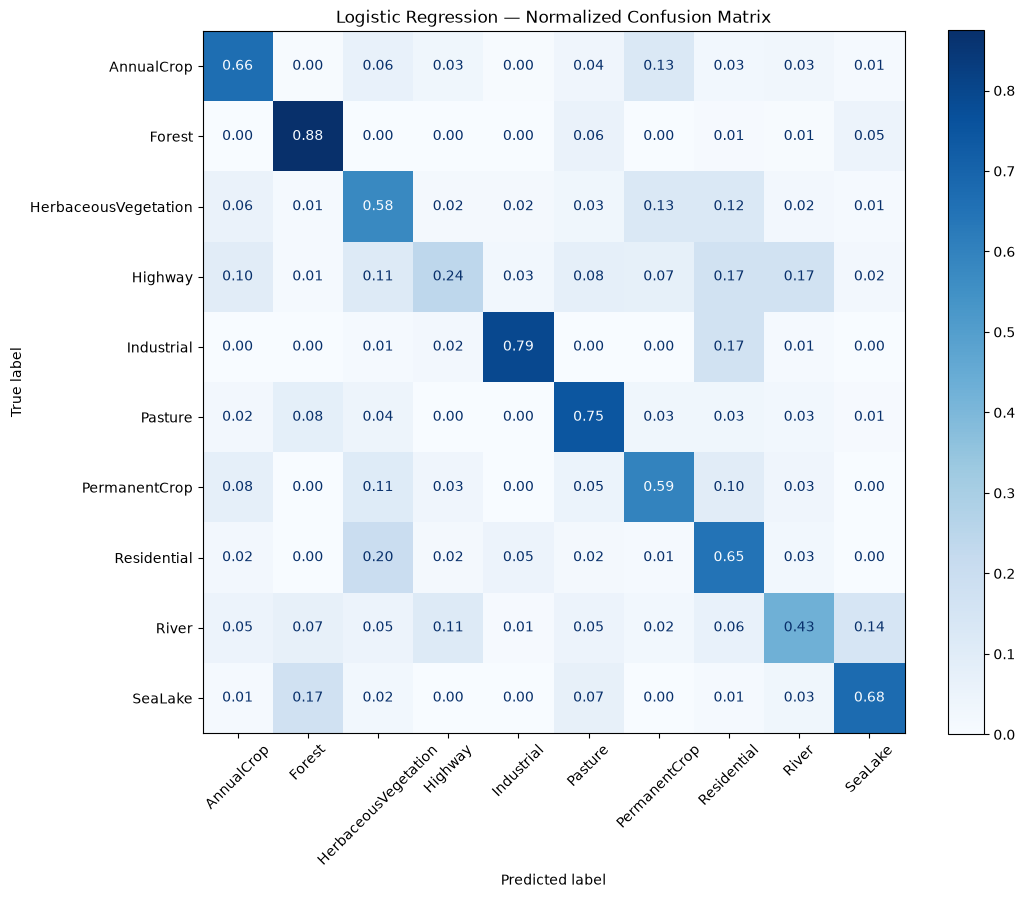

In [43]:
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

fig, ax = plt.subplots(figsize=(11, 9))

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=class_names,
)

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45,
)

ax.set_title(
    "Logistic Regression — Normalized Confusion Matrix"
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "logistic_regression_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [44]:
off_diagonal = cm_counts.copy()
np.fill_diagonal(off_diagonal, 0)

misclassification_records = []

for true_index, predicted_index in np.argwhere(
    off_diagonal > 0
):
    misclassification_records.append(
        {
            "actual_class": class_names[true_index],
            "predicted_class": class_names[predicted_index],
            "misclassified_images": off_diagonal[
                true_index,
                predicted_index,
            ],
        }
    )

top_confusions = (
    pd.DataFrame(misclassification_records)
    .sort_values(
        "misclassified_images",
        ascending=False,
    )
    .head(10)
    .reset_index(drop=True)
)

display(top_confusions)

,actual_class,predicted_class,misclassified_images
0,Residential,HerbaceousVegetation,90
1,SeaLake,Forest,77
2,Highway,River,64
3,Highway,Residential,63
4,Industrial,Residential,62
5,AnnualCrop,PermanentCrop,58
6,HerbaceousVegetation,PermanentCrop,57
7,HerbaceousVegetation,Residential,56
8,River,SeaLake,54
9,River,Highway,42


## 9. Visual Error Analysis

This section investigates representative validation samples that were incorrectly classified by the Logistic Regression baseline.

The objective is to identify visual patterns that may explain the most frequent classification errors and understand the limitations of global colour histogram features.

In [45]:
validation_results = validation_manifest.copy()

validation_results["actual_label"] = y_validation
validation_results["predicted_label"] = validation_predictions

validation_errors = validation_results.loc[
    validation_results["actual_label"]
    != validation_results["predicted_label"]
].copy()

print(f"Total misclassified images: {len(validation_errors):,}")
print(
    f"Validation error rate: "
    f"{len(validation_errors) / len(validation_results):.2%}"
)

display(
    validation_errors[
        ["filepath", "actual_label", "predicted_label"]
    ].head()
)

Total misclassified images: 1,508
Validation error rate: 37.23%


,filepath,actual_label,predicted_label
0,data/raw/EuroSAT_RGB/Highway/Highway_1024.jpg,Highway,River
3,data/raw/EuroSAT_RGB/PermanentCrop/PermanentCr...,PermanentCrop,Residential
6,data/raw/EuroSAT_RGB/Industrial/Industrial_158...,Industrial,Highway
9,data/raw/EuroSAT_RGB/HerbaceousVegetation/Herb...,HerbaceousVegetation,AnnualCrop
10,data/raw/EuroSAT_RGB/River/River_2458.jpg,River,HerbaceousVegetation


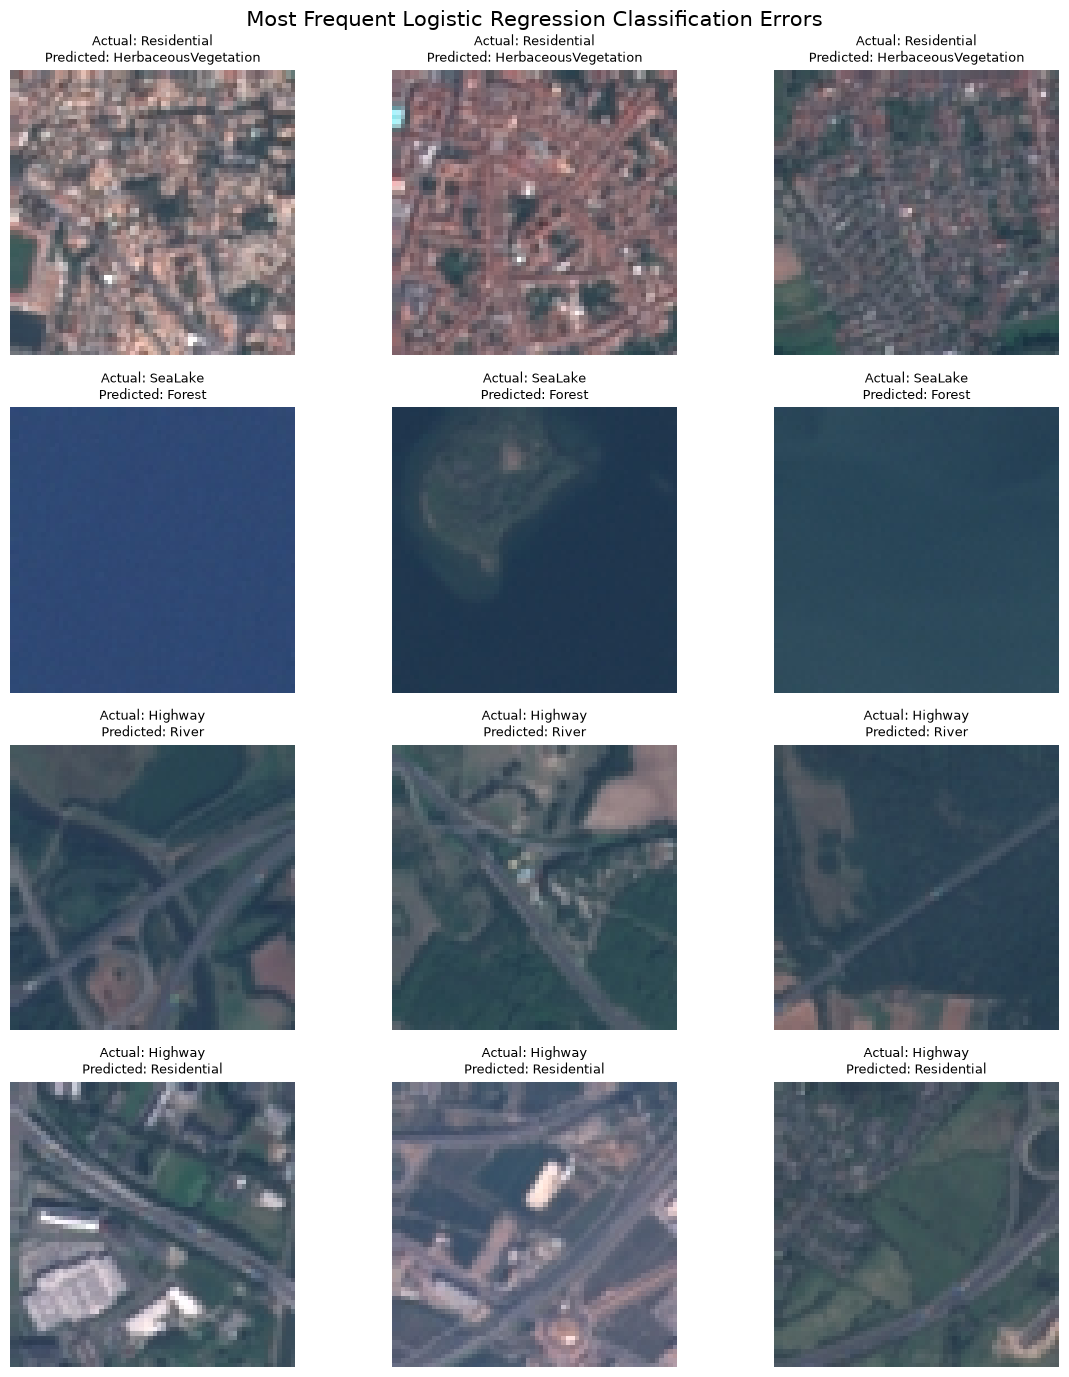

In [ ]:
pairs_to_inspect = top_confusions.head(4)

n_rows = len(pairs_to_inspect)
n_cols = 3

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(12, 3.5 * n_rows),
)

rng = np.random.default_rng(42)

for row_index, pair in enumerate(
    pairs_to_inspect.itertuples(index=False)
):
    pair_errors = validation_errors.loc[
        (validation_errors["actual_label"] == pair.actual_class)
        & (
            validation_errors["predicted_label"]
            == pair.predicted_class
        )
    ]

    sample_size = min(n_cols, len(pair_errors))

    selected_errors = pair_errors.sample(
        n=sample_size,
        random_state=42,
    )

    for col_index in range(n_cols):
        ax = axes[row_index, col_index]

        if col_index >= sample_size:
            ax.axis("off")
            continue

        row = selected_errors.iloc[col_index]
        image_path = PROJECT_ROOT / row["filepath"]

        with Image.open(image_path) as image:
            ax.imshow(image.convert("RGB"))

        ax.set_title(
            f"Actual: {row['actual_label']}\n"
            f"Predicted: {row['predicted_label']}",
            fontsize=9,
        )
        ax.axis("off")

fig.suptitle(
    "Most Frequent Logistic Regression Classification Errors",
    fontsize=15,
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "logistic_regression_error_examples.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

## 10. Logistic Regression Baseline — Experimental Findings

### Validation Performance

The Logistic Regression baseline achieved the following results:

| Metric | Validation Score |
|---|---:|
| Accuracy | 0.6277 |
| Macro F1-score | 0.6164 |
| Weighted F1-score | 0.6199 |

The model successfully identifies all ten land cover categories, although its performance varies considerably across classes.

### Per-Class Performance

- **Best-performing classes:** Industrial (F1-score: 0.8285) and Forest (F1-score: 0.8016).
- **Most challenging class:** Highway (F1-score: 0.3214).
- River also presents classification difficulties, with an F1-score of 0.4749.

### Most Frequent Classification Errors

The most frequent confusions include:

| Actual Class | Predicted Class | Errors |
|---|---|---:|
| Residential | HerbaceousVegetation | 90 |
| SeaLake | Forest | 77 |
| Highway | River | 64 |
| Highway | Residential | 63 |
| Industrial | Residential | 62 |

### Visual Error Analysis

Inspection of representative misclassified images reveals several potentially challenging patterns:

- Residential images may contain vegetation and mixed urban surfaces.
- SeaLake images may exhibit dark RGB distributions similar to some forest images.
- Highway images often contain roads surrounded by agricultural, urban, or natural surfaces.
- Industrial and Residential images may share similar built-up structures.

### Model Limitations

The RGB histogram representation captures global colour distributions but discards spatial information.

Consequently, the classifier cannot explicitly learn the arrangement of roads, buildings, vegetation, or water bodies.

This limitation provides motivation for investigating feature extraction methods that preserve more spatial and structural information.

### Conclusion

The Logistic Regression classifier establishes an initial baseline for the EuroSAT RGB classification task.

Its results demonstrate that global colour distributions contain useful information for land cover classification, but they are insufficient to reliably distinguish certain visually similar categories.

Further experiments will investigate alternative classifiers and spatial feature extraction techniques.